# Clustering với k-Means

In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

np.set_printoptions(precision=3, suppress=True)

## 1. Dữ liệu giả định

**Giả sử có 3 tập**
1. Set 1: 50 điểm
1. Set 2: 75 điểm
1. Set 3: 100 điểm

In [2]:
np.random.seed(1)
x1,y1 = np.random.normal(loc=2,scale=1,size=50), np.random.normal(loc=5,scale=1,size=50)
x2,y2 = np.random.normal(loc=5,scale=1,size=75), np.random.normal(loc=1,scale=1,size=75)
x3,y3 = np.random.normal(loc=8,scale=1,size=100), np.random.normal(loc=7,scale=1,size=100)

**=== Hiển thị 3 tập để kiểm tra ===**

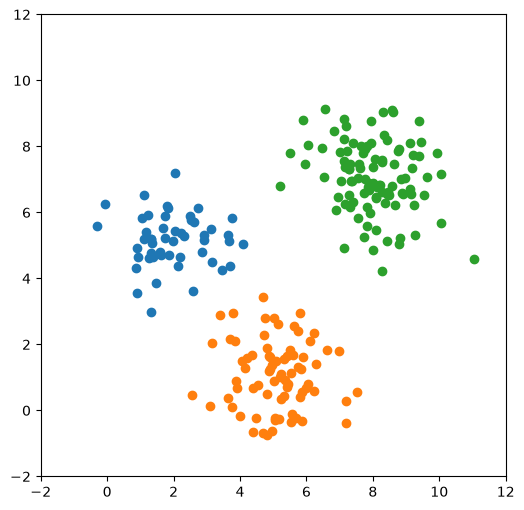

In [3]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(x1, y1)
plt.scatter(x2, y2)
plt.scatter(x3, y3)
plt.show()

### Ghép nối dữ liệu lại thành 1 tập chưa được clustered

In [4]:
dat1 = np.stack([x1, y1]).T


In [6]:
dat2 = np.stack([x2,y2]).T
dat3 = np.stack([x3,y3]).T

**=== Tập dữ liệu giả định có 225 dòng, 2 cột (x,y) ===**

In [7]:
dat = np.concatenate([dat1, dat2, dat3], axis=0)

print(dat.shape)
print(dat[:5])


(225, 2)
[[3.624 5.3  ]
 [1.388 4.648]
 [1.472 3.857]
 [0.927 4.651]
 [2.865 4.791]]


### Sắp ngẫu nhiên các dòng

In [8]:
np.random.seed(2)
np.random.seed(2)
np.random.shuffle(dat)

### Kiểm tra lại với biểu đồ scatter

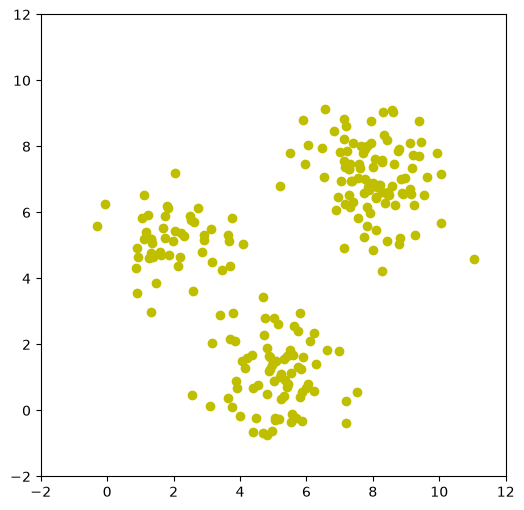

In [11]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.show()

## 2. Thực hiện phân cụm

### 2.1. Giả sử K=3 và tìm 3 điểm ban đầu ngẫu nhiên

In [12]:
K = 3

In [13]:
np.random.seed(30)
np.random.seed(30)

# Chọn ngẫu nhiên 3 vị trí khác nhau trong dữ liệu
vi_tri = np.random.choice(len(dat), size=K, replace=False)

print("Vị trí được chọn:", vi_tri)


Vị trí được chọn: [  8 180 170]


**Gán các trung tâm cho 3 điểm này**

In [14]:
centroids = dat[vi_tri].copy()

print("Tọa độ 3 tâm ban đầu:")
print(centroids)


Tọa độ 3 tâm ban đầu:
[[5.338 0.438]
 [2.617 5.698]
 [4.9   1.243]]


**=== Vẽ K điểm centroids ban đầu lên biểu đồ ===**

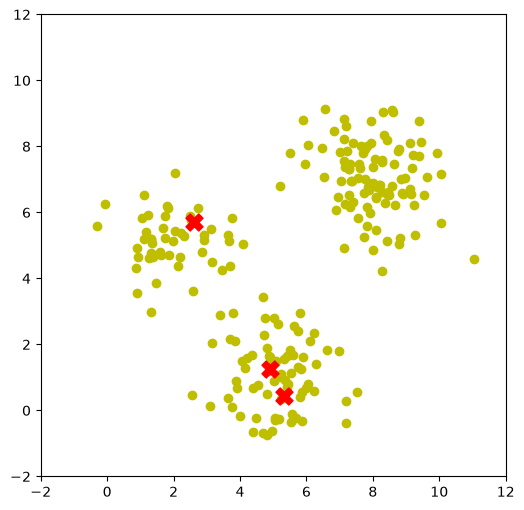

In [15]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.scatter(
    centroids[:, 0], centroids[:, 1],
    color='red', marker='X', s=150
)

plt.show()

### 2.2. Tiến hành gom cụm lần 1

**=== Khởi tạo K danh sách rỗng (để chứa các điểm của mỗi cluster) ===**

In [16]:
cList = [[] for _ in range(K)]

print(cList)

print(cList)

[[], [], []]
[[], [], []]


**=== Với mỗi sample, tìm xem nó gần điểm centroid nào nhất ===**

In [18]:
for sample in dat:
    # Tính bình phương khoảng cách đến từng tâm
    khoang_cach = np.sum((sample - centroids)**2, axis=1)

    # Tìm vị trí của tâm gần nhất
    cum_gan_nhat = np.argmin(khoang_cach)

    # Đưa điểm đang xét vào cụm đó
    cList[cum_gan_nhat].append(sample)

In [19]:
# Thử kiểm tra lại mỗi list
for i in range(K): print(len(cList[i]))

29
138
58


**=== Thử lấy cluster đầu tiên ra và đánh giá ===**

In [20]:
np.stack(cList[0]).shape

(29, 2)

In [21]:
# Tọa độ của điểm centroid mới
np.stack(cList[0]).mean(axis=0)

array([5.584, 0.19 ])

**=== Tính lại các điểm centroids ===**

In [22]:
for i in range(K):
    if len(cList[i]) > 0:
        centroids[i] = np.stack(cList[i]).mean(axis=0)

print(centroids)

print(centroids)

[[5.584 0.19 ]
 [5.764 6.535]
 [5.594 2.377]]
[[5.584 0.19 ]
 [5.764 6.535]
 [5.594 2.377]]


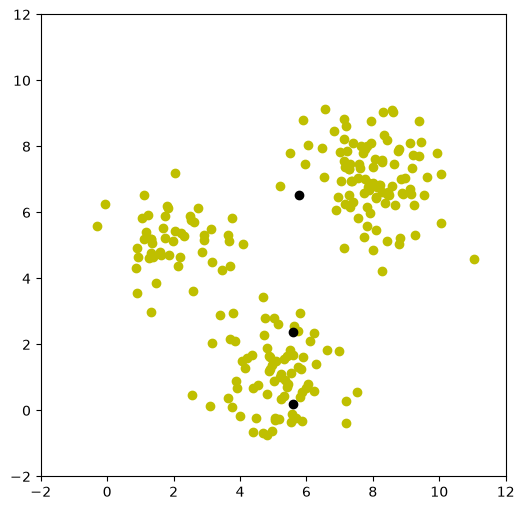

In [23]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.scatter(centroids[:,0], centroids[:,1], color='k')

plt.show()

### 2.3. Tiến hành gom cụm lần 2

**=== Tiếp tục khởi tạo K list rỗng để chứa các cluster mới ===**

In [24]:
cList = [[] for _ in range(K)]
for sample in dat:
    kq = np.sum((sample - centroids)**2, axis=1)
    min_d_idx = np.argmin(kq)
    cList[min_d_idx].append(sample)

# Tính giá trị của các centroids mới
centroids = [np.stack(cList[i]).mean(axis=0) for i in range(K)]
centroids = np.stack(centroids)
print(centroids)

[[5.099 0.36 ]
 [6.268 6.612]
 [4.451 2.574]]


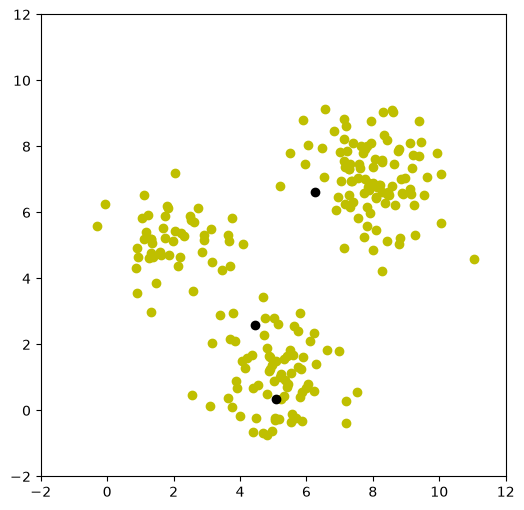

In [25]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.scatter(centroids[:,0], centroids[:,1], color='k')

plt.show()

### 2.4. Tiến hành gom cụm lần 3

**=== Tiếp tục khởi tạo K list rỗng để chứa các cluster mới ===**

In [26]:
cList = [[] for _ in range(K)]
for sample in dat:
    kq = np.sum((sample - centroids)**2, axis=1)
    min_d_idx = np.argmin(kq)
    cList[min_d_idx].append(sample)

centroids = [np.stack(cList[i]).mean(axis=0) for i in range(K)]
centroids = np.stack(centroids)
print(centroids)

[[5.225 0.569]
 [7.744 7.031]
 [2.898 4.079]]


**==> Nhận xét: các giá trị trung tâm gần như ít thay đổi**

In [29]:
# Lấy ra các cluster

clusters = [
    np.array(cList[i]).reshape(-1, 2)
    for i in range(K)
]

for i in range(K):
    print(f"Cụm {i + 1}: {len(clusters[i])} điểm")

Cụm 1: 52 điểm
Cụm 2: 105 điểm
Cụm 3: 68 điểm


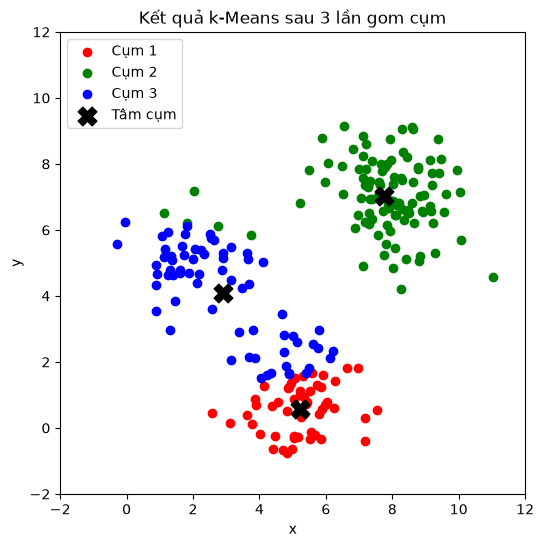

In [30]:
plt.figure(figsize=(6, 6))
plt.xlim([-2, 12])
plt.ylim([-2, 12])

mau = ['red', 'green', 'blue']

for i in range(K):
    plt.scatter(
        clusters[i][:, 0],
        clusters[i][:, 1],
        color=mau[i],
        label=f"Cụm {i + 1}"
    )

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color='black',
    marker='X',
    s=180,
    label='Tâm cụm'
)

plt.title("Kết quả k-Means sau 3 lần gom cụm")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()